<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 272  Features: 2  Clusters K = 2 

Iteration   1  Log-likelihood = -1514.5072
Iteration   2  Log-likelihood = -1259.3062
Iteration   3  Log-likelihood = -1211.2400
Iteration   5  Log-likelihood = -1142.9621
Iteration  10  Log-likelihood = -1130.2640
Converged at iteration 12  Log-likelihood = -1130.2640

Final parameters:
Cluster 1 (short)
  weight = 0.356
  mean   = eruptions 2.036, waiting 54.479
Cluster 2 (long)
  weight = 0.644
  mean   = eruptions 4.290, waiting 79.968

Points in each cluster:
  Cluster 1 (short): 97 points
  Cluster 2 (long): 175 points

New point (eruptions=4.0, waiting=80): cluster = Cluster 2 (long), probability = 1.000


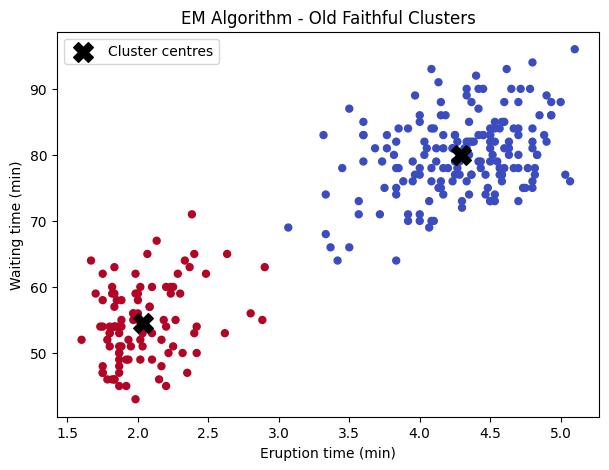

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Dataset: Old Faithful Geyser (faithful.csv)
# eruptions = eruption time (minutes), waiting = waiting time to next eruption (minutes)

# ---- 1. Load CSV (Download if not exists local) ----
csv_path = 'faithful.csv'
if not os.path.exists(csv_path):
    print("Downloading faithful.csv...")
    url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/geyser.csv"
    # Note: Seaborn's geyser dataset has columns 'duration' (eruptions) and 'waiting'
    df = pd.read_csv(url)
    df = df.rename(columns={'duration': 'eruptions'})
    df.to_csv(csv_path, index=False)
else:
    df = pd.read_csv(csv_path)

X = df[['eruptions', 'waiting']].values.astype(float)
n, d = X.shape
K = 2                                   # number of clusters (Gaussians)
print("Rows:", n, " Features:", d, " Clusters K =", K, "\n")

# ---- 2. Gaussian probability for 2-D data ----
def gaussian(X, mu, cov):
    diff = X - mu
    inv = np.linalg.inv(cov)
    expo = -0.5 * np.sum(diff @ inv * diff, axis=1)
    return np.exp(expo) / np.sqrt(((2 * np.pi) ** d) * np.linalg.det(cov))

# ---- 3. Initialise parameters ----
np.random.seed(42)
mu = X[np.random.choice(n, K, replace=False)]          # random starting means
cov = np.array([np.cov(X.T) for _ in range(K)])        # starting covariances
pi = np.ones(K) / K                                    # equal mixing weights

# ---- 4. EM algorithm ----
prev_ll = -np.inf
for it in range(1, 101):
    # E-step: probability that each point belongs to each cluster
    resp = np.column_stack([pi[k] * gaussian(X, mu[k], cov[k]) for k in range(K)])
    total = resp.sum(axis=1, keepdims=True)
    resp = resp / total

    # log-likelihood (how well the model fits the data)
    ll = np.sum(np.log(total))

    # M-step: update parameters using those probabilities
    Nk = resp.sum(axis=0)
    pi = Nk / n
    mu = (resp.T @ X) / Nk[:, None]
    for k in range(K):
        diff = X - mu[k]
        cov[k] = (resp[:, k, None] * diff).T @ diff / Nk[k]

    if it <= 3 or it % 5 == 0:
        print(f"Iteration {it:3d}  Log-likelihood = {ll:.4f}")

    # stop when no more improvement
    if abs(ll - prev_ll) < 1e-6:
        print(f"Converged at iteration {it}  Log-likelihood = {ll:.4f}")
        break
    prev_ll = ll

# ---- 5. Final parameters ----
order = np.argsort(mu[:, 0])            # list shorter eruptions first
print("\nFinal parameters:")
for name, k in zip(['Cluster 1 (short)', 'Cluster 2 (long)'], order):
    print(f"{name}")
    print(f"  weight = {pi[k]:.3f}")
    print(f"  mean   = eruptions {mu[k][0]:.3f}, waiting {mu[k][1]:.3f}")

# ---- 6. Assign each point to its most likely cluster ----
labels = resp.argmax(axis=1)
print("\nPoints in each cluster:")
for name, k in zip(['Cluster 1 (short)', 'Cluster 2 (long)'], order):
    print(f"  {name}: {int(np.sum(labels == k))} points")

# ---- 7. Classify a new eruption ----
new = np.array([[4.0, 80.0]])
p = np.array([pi[k] * gaussian(new, mu[k], cov[k])[0] for k in range(K)])
p = p / p.sum()
print(f"\nNew point (eruptions=4.0, waiting=80): cluster = "
      f"{'Cluster 2 (long)' if p.argmax() == order[1] else 'Cluster 1 (short)'}, "
      f"probability = {p.max():.3f}")

# ---- 8. Plot ----
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='coolwarm', s=25)
plt.scatter(mu[:, 0], mu[:, 1], c='black', marker='X', s=200, label='Cluster centres')
plt.xlabel('Eruption time (min)')
plt.ylabel('Waiting time (min)')
plt.title('EM Algorithm - Old Faithful Clusters')
plt.legend()
plt.show()